# 계절별 독감 유행 시작 시점 분석

**질문**: 독감 유사 질환(ILI) 발생률이 언제 유행 기준을 넘는지, 시즌마다 얼마나 다를까?

> ⚠️ 이 노트북의 자료는 교재 실습용 **합성(가짜) 데이터**입니다. 실제 감시 자료가 아닙니다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('data/flu_weekly_synthetic.csv')
df.head()

,season,season_week,ili_per_1000
0,2023-24,1,2.7
1,2023-24,2,4.4
2,2023-24,3,1.1
3,2023-24,4,6.7
4,2023-24,5,6.2


## 1. 시즌별 주간 발생률

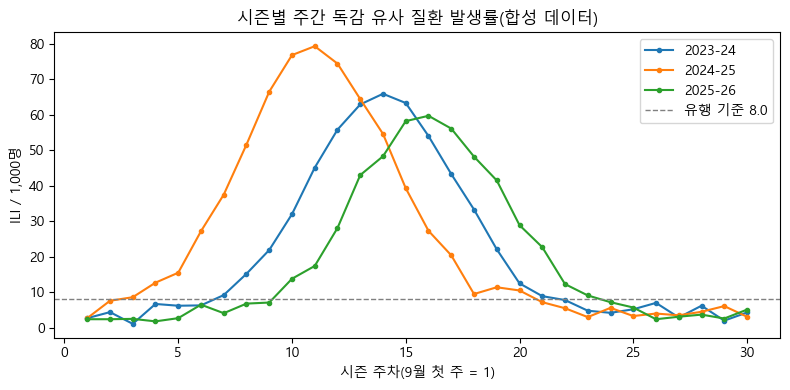

In [2]:
THRESHOLD = 8.0  # 유행 기준(1,000명당, 가정값)

fig, ax = plt.subplots(figsize=(8, 4))
for season, g in df.groupby('season'):
    ax.plot(g['season_week'], g['ili_per_1000'], marker='o', ms=3, label=season)
ax.axhline(THRESHOLD, color='gray', ls='--', lw=1, label=f'유행 기준 {THRESHOLD}')
ax.set_xlabel('시즌 주차(9월 첫 주 = 1)')
ax.set_ylabel('ILI / 1,000명')
ax.set_title('시즌별 주간 독감 유사 질환 발생률(합성 데이터)')
ax.legend()
fig.tight_layout()
fig.savefig('images/weekly-trend.png', dpi=120)
plt.show()

## 2. 유행 시작 주차

발생률이 **2주 연속** 기준을 넘은 첫 주를 유행 시작으로 정의합니다.

In [3]:
def onset_week(g, thr=THRESHOLD):
    above = (g['ili_per_1000'] > thr).tolist()
    for i in range(len(above) - 1):
        if above[i] and above[i + 1]:
            return int(g['season_week'].iloc[i])
    return None

onset = (df.sort_values('season_week').groupby('season')
           .apply(onset_week, include_groups=False).rename('onset_week').reset_index())
peak = df.loc[df.groupby('season')['ili_per_1000'].idxmax(), ['season', 'season_week', 'ili_per_1000']]
summary = onset.merge(peak.rename(columns={'season_week': 'peak_week', 'ili_per_1000': 'peak_value'}), on='season')
summary

,season,onset_week,peak_week,peak_value
0,2023-24,7,14,65.9
1,2024-25,3,11,79.3
2,2025-26,10,16,59.7


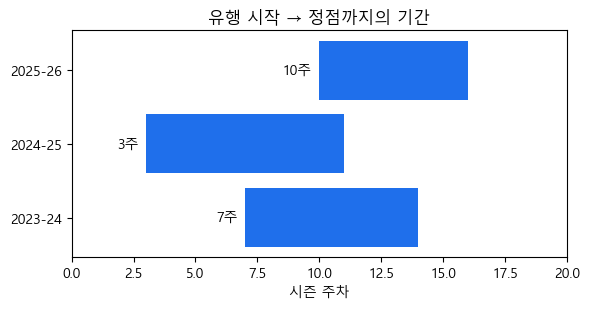

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(summary['season'], summary['peak_week'] - summary['onset_week'], left=summary['onset_week'], color='#1f6feb')
for _, r in summary.iterrows():
    ax.text(r['onset_week'] - 0.3, r['season'], f"{r['onset_week']}주", ha='right', va='center')
ax.set_xlim(0, 20)
ax.set_xlabel('시즌 주차')
ax.set_title('유행 시작 → 정점까지의 기간')
fig.tight_layout()
fig.savefig('images/onset-by-season.png', dpi=120)
plt.show()

## 3. 결과와 배운 점

- 세 시즌 모두 정점보다 6~8주 먼저 유행 기준을 넘었다.
- 정점 주차가 빠른 시즌일수록 유행 시작도 빨랐다.
- **배운 점**: '2주 연속' 같은 정의를 바꾸면 시작 주차가 달라진다. 정의를 결과와 함께 공개해야 한다.